In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 05 — Compare the three models

Run this **after** 04a, 04b and 04c have finished. It:

1. Collects validation results (OA, mIoU, per-class IoU, size, training time) into one table.
2. Overlays the training curves.
3. Evaluates **all three on the test set** (OA, mIoU, per-class IoU and F1) — the numbers the report asks for.
4. Breaks test mIoU down **per test region** (regions unlike the training data) and **per month** (seasonal effects) — evidence for the critical discussion.
5. Shows the same test patches predicted by all three models side by side.

**Rule:** choose the best model by **validation** mIoU; the test numbers are reported, not used for choosing.

In [1]:
import sys, json
sys.path.append(".")
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
import train_lib as tl
from train_lib import NC, DEV
from preprocess import CLASSES, IGNORE, COLORS, load_stats

RUNS = {
    "U-Net / ResNet-34":      ("A_unet_resnet34",         lambda: smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=NC)),
    "DeepLabV3+ / ResNet-50": ("B_deeplabv3plus_resnet50", lambda: smp.DeepLabV3Plus("resnet50", encoder_weights=None, in_channels=3, classes=NC)),
    "SegFormer / MiT-B2":     ("C_segformer_mitb2",        lambda: smp.Segformer("mit_b2", encoder_weights=None, in_channels=3, classes=NC)),
}
DATA = Path("data")
stats = load_stats(DATA / "norm_stats.json")
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)
available = {k: v for k, v in RUNS.items() if (Path("runs") / v[0] / "best.pth").exists()}
print("Finished models:", list(available) or "none yet")

Finished models: ['U-Net / ResNet-34', 'DeepLabV3+ / ResNet-50', 'SegFormer / MiT-B2']


## 1. Validation summary

In [2]:
rows, iou_rows = [], {}
for name, (run, _) in available.items():
    m = json.load(open(Path("runs") / run / "metrics.json"))
    rows.append({"model": name, "val OA": m["val_oa"], "val mIoU": m["val_miou"],
                 "params (M)": m["params_M"], "best epoch": m["best_epoch"],
                 "epochs run": m["epochs_run"], "train time (min)": m["train_minutes"]})
    iou_rows[name] = m["per_class_iou"]
val_table = pd.DataFrame(rows).set_index("model").sort_values("val mIoU", ascending=False)
val_iou = pd.DataFrame(iou_rows).T[CLASSES].round(3)
val_table.to_csv("runs/comparison_val.csv"); val_iou.to_csv("runs/comparison_val_per_class_iou.csv")
display(val_table); print("Validation IoU per class"); display(val_iou)
print("Best model by validation mIoU:", val_table.index[0])

,val OA,val mIoU,params (M),best epoch,epochs run,train time (min)
model,,,,,,
SegFormer / MiT-B2,0.7313,0.5148,24.7,6,15,3.0
U-Net / ResNet-34,0.7101,0.4958,24.4,21,30,5.7
DeepLabV3+ / ResNet-50,0.7208,0.4931,26.7,22,31,6.1


Validation IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
U-Net / ResNet-34,0.405,0.290,0.495,0.729,0.223,0.764,0.565
DeepLabV3+ / ResNet-50,0.438,0.219,0.491,0.754,0.206,0.748,0.597
SegFormer / MiT-B2,0.448,0.221,0.571,0.738,0.209,0.752,0.665


Best model by validation mIoU: SegFormer / MiT-B2


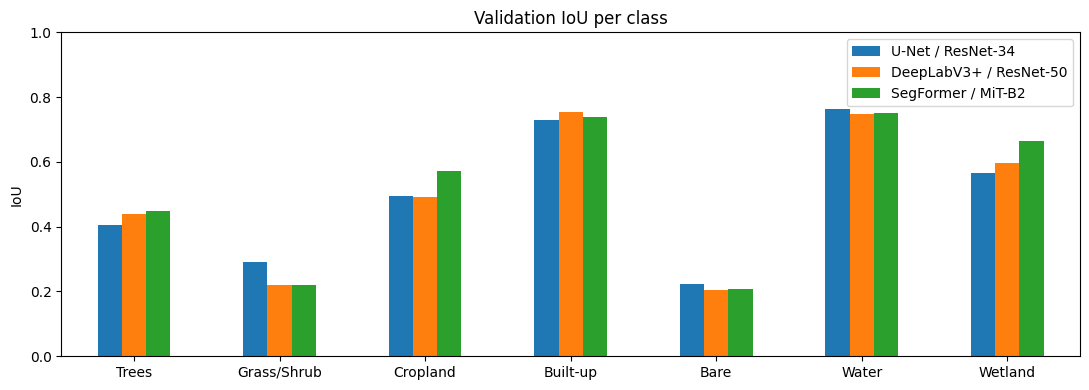

In [3]:
ax = val_iou.T.plot.bar(figsize=(11, 4), rot=0, title="Validation IoU per class")
ax.set_ylabel("IoU"); ax.set_ylim(0, 1); plt.tight_layout()
plt.savefig("runs/comparison_val_iou.png", dpi=150); plt.show()

## 2. Training curves side by side

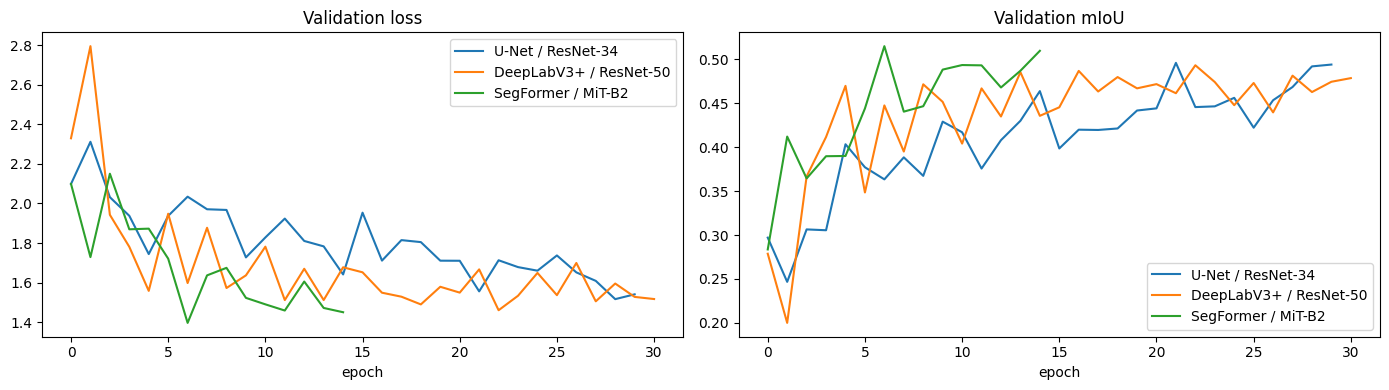

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, (run, _) in available.items():
    h = pd.read_csv(Path("runs") / run / "history.csv")
    ax[0].plot(h.epoch, h.val_loss, label=name)
    ax[1].plot(h.epoch, h.val_miou, label=name)
ax[0].set_title("Validation loss"); ax[1].set_title("Validation mIoU")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("runs/comparison_curves.png", dpi=150); plt.show()

## 3. Test set — all models

Test patches are loaded once (all 12 months). For each model we keep the confusion matrix overall, per region and per month.

In [5]:
test_files = index[index.split == "test"].reset_index(drop=True)
test_ds = tl.EvalPatches(test_files.file, DATA, stats, "loading test")
region_of = np.repeat(test_files.region.values, 12)          # sample k -> region
month_of = np.array(test_ds.month)
test_dl = torch.utils.data.DataLoader(test_ds, 32, shuffle=False)

def miou(cm): return float(tl.scores(cm)[1].mean())

results = {}
for name, (run, make) in available.items():
    model = make().to(DEV)
    model.load_state_dict(torch.load(Path("runs") / run / "best.pth", map_location=DEV)); model.eval()
    cm_all = torch.zeros(NC, NC, dtype=torch.long, device=DEV)
    cm_reg = {r: torch.zeros_like(cm_all) for r in np.unique(region_of)}
    cm_mon = {m: torch.zeros_like(cm_all) for m in range(12)}
    k = 0
    with torch.no_grad():
        for x, y in test_dl:
            x, y = x.to(DEV), y.to(DEV)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
                p = model(x).argmax(1)
            for b in range(len(x)):
                c = tl.confusion(p[b], y[b])
                cm_all += c; cm_reg[region_of[k]] += c; cm_mon[month_of[k]] += c; k += 1
    oa, iou, f1 = tl.scores(cm_all)
    results[name] = dict(cm=cm_all, oa=oa, iou=iou, f1=f1,
                         region={r: miou(c) for r, c in cm_reg.items()},
                         month={m + 1: miou(c) for m, c in cm_mon.items()})
    print(f"{name:24s} test OA {oa:.3f} | test mIoU {iou.mean():.3f}")
    del model
    if DEV == "cuda": torch.cuda.empty_cache()

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

U-Net / ResNet-34        test OA 0.717 | test mIoU 0.577
DeepLabV3+ / ResNet-50   test OA 0.740 | test mIoU 0.605
SegFormer / MiT-B2       test OA 0.666 | test mIoU 0.534


In [6]:
test_table = pd.DataFrame({n: {"test OA": r["oa"], "test mIoU": r["iou"].mean()} for n, r in results.items()}).T.round(3)
test_iou = pd.DataFrame({n: r["iou"] for n, r in results.items()}, index=CLASSES).T.round(3)
test_f1 = pd.DataFrame({n: r["f1"] for n, r in results.items()}, index=CLASSES).T.round(3)
test_table.to_csv("runs/comparison_test.csv"); test_iou.to_csv("runs/comparison_test_iou.csv"); test_f1.to_csv("runs/comparison_test_f1.csv")
display(test_table); print("Test IoU per class"); display(test_iou); print("Test F1 per class"); display(test_f1)

,test OA,test mIoU
U-Net / ResNet-34,0.717,0.577
DeepLabV3+ / ResNet-50,0.740,0.605
SegFormer / MiT-B2,0.666,0.534


Test IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
U-Net / ResNet-34,0.555,0.199,0.594,0.710,0.866,0.739,0.375
DeepLabV3+ / ResNet-50,0.578,0.296,0.615,0.768,0.916,0.791,0.269
SegFormer / MiT-B2,0.554,0.211,0.591,0.694,0.650,0.762,0.275


Test F1 per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
U-Net / ResNet-34,0.714,0.332,0.745,0.830,0.928,0.850,0.545
DeepLabV3+ / ResNet-50,0.733,0.457,0.762,0.869,0.956,0.883,0.424
SegFormer / MiT-B2,0.713,0.348,0.743,0.819,0.788,0.865,0.431


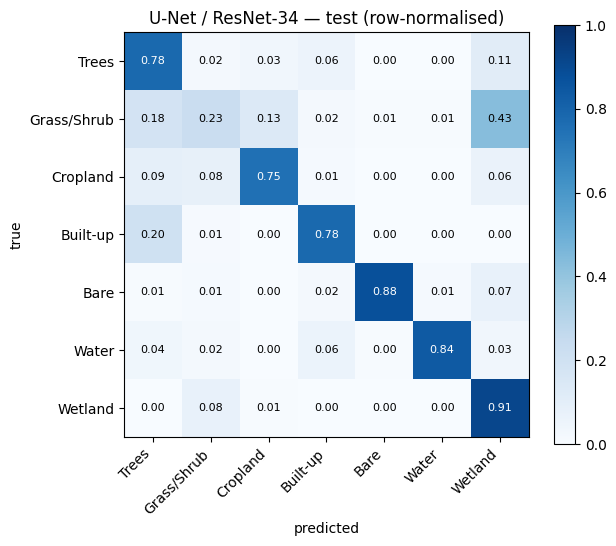

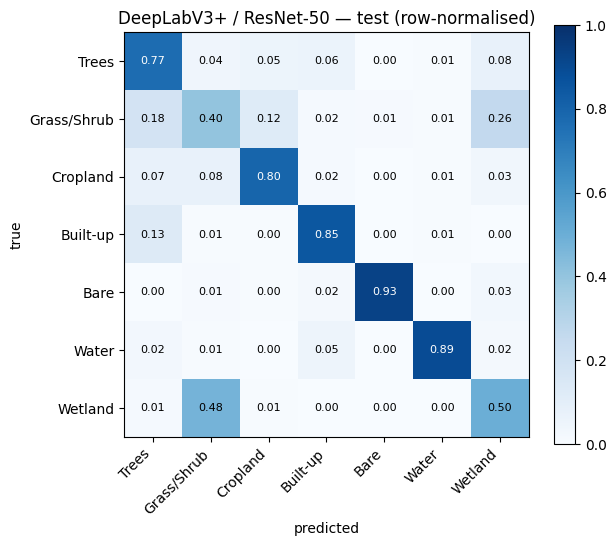

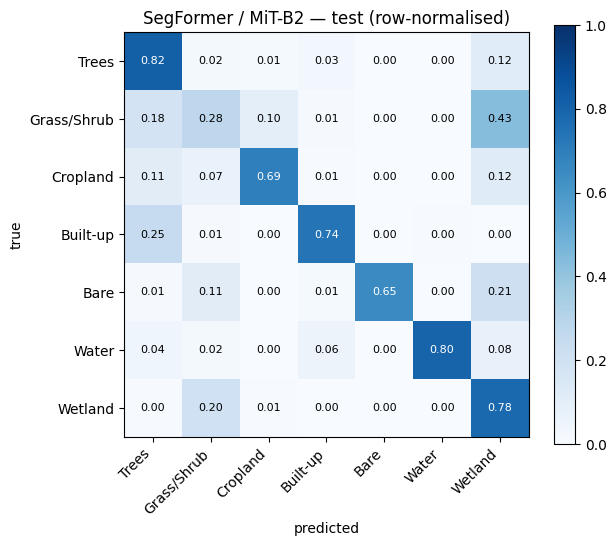

In [7]:
for name, r in results.items():
    tl.plot_confusion(r["cm"], Path("runs") / f"test_confusion_{RUNS[name][0]}.png", f"{name} — test (row-normalised)")

## 4. Per test region and per month

* **Per region:** test regions were chosen to be unlike most training data (desert city, deltas, steppe-like plain…). Low values here = poor generalisation.
* **Per month:** a dip in winter/early spring usually means **seasonal confusion** (bare fields, frozen or wet soil, leafless trees) — not real land-cover change.

Test mIoU per region


,U-Net / ResNet-34,DeepLabV3+ / ResNet-50,SegFormer / MiT-B2
black_forest,0.222,0.240,0.222
cairo,0.274,0.319,0.262
hungary_plain,0.345,0.347,0.301
mekong_delta,0.328,0.325,0.299
namib_desert,0.130,0.137,0.097
okavango,0.080,0.161,0.115


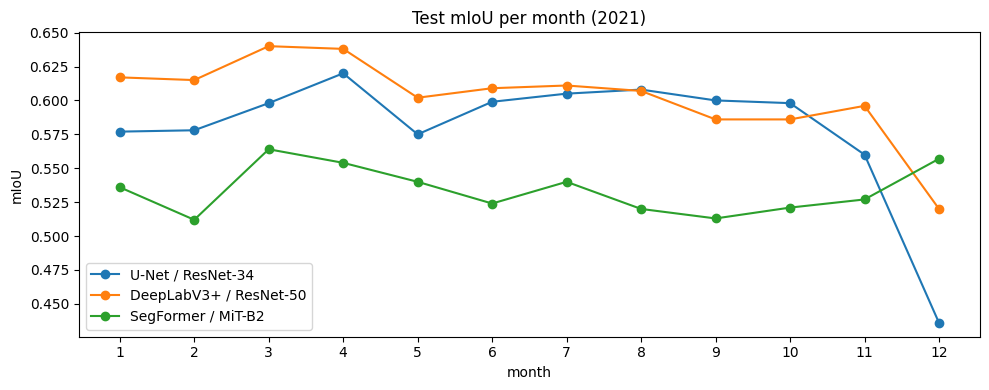

In [8]:
by_region = pd.DataFrame({n: r["region"] for n, r in results.items()}).round(3)
by_month = pd.DataFrame({n: r["month"] for n, r in results.items()}).round(3)
by_region.to_csv("runs/comparison_test_by_region.csv"); by_month.to_csv("runs/comparison_test_by_month.csv")
print("Test mIoU per region"); display(by_region)

ax = by_month.plot(marker="o", figsize=(10, 4), title="Test mIoU per month (2021)")
ax.set_xlabel("month"); ax.set_ylabel("mIoU"); ax.set_xticks(range(1, 13)); plt.tight_layout()
plt.savefig("runs/comparison_test_by_month.png", dpi=150); plt.show()

## 5. Same test patches, three models

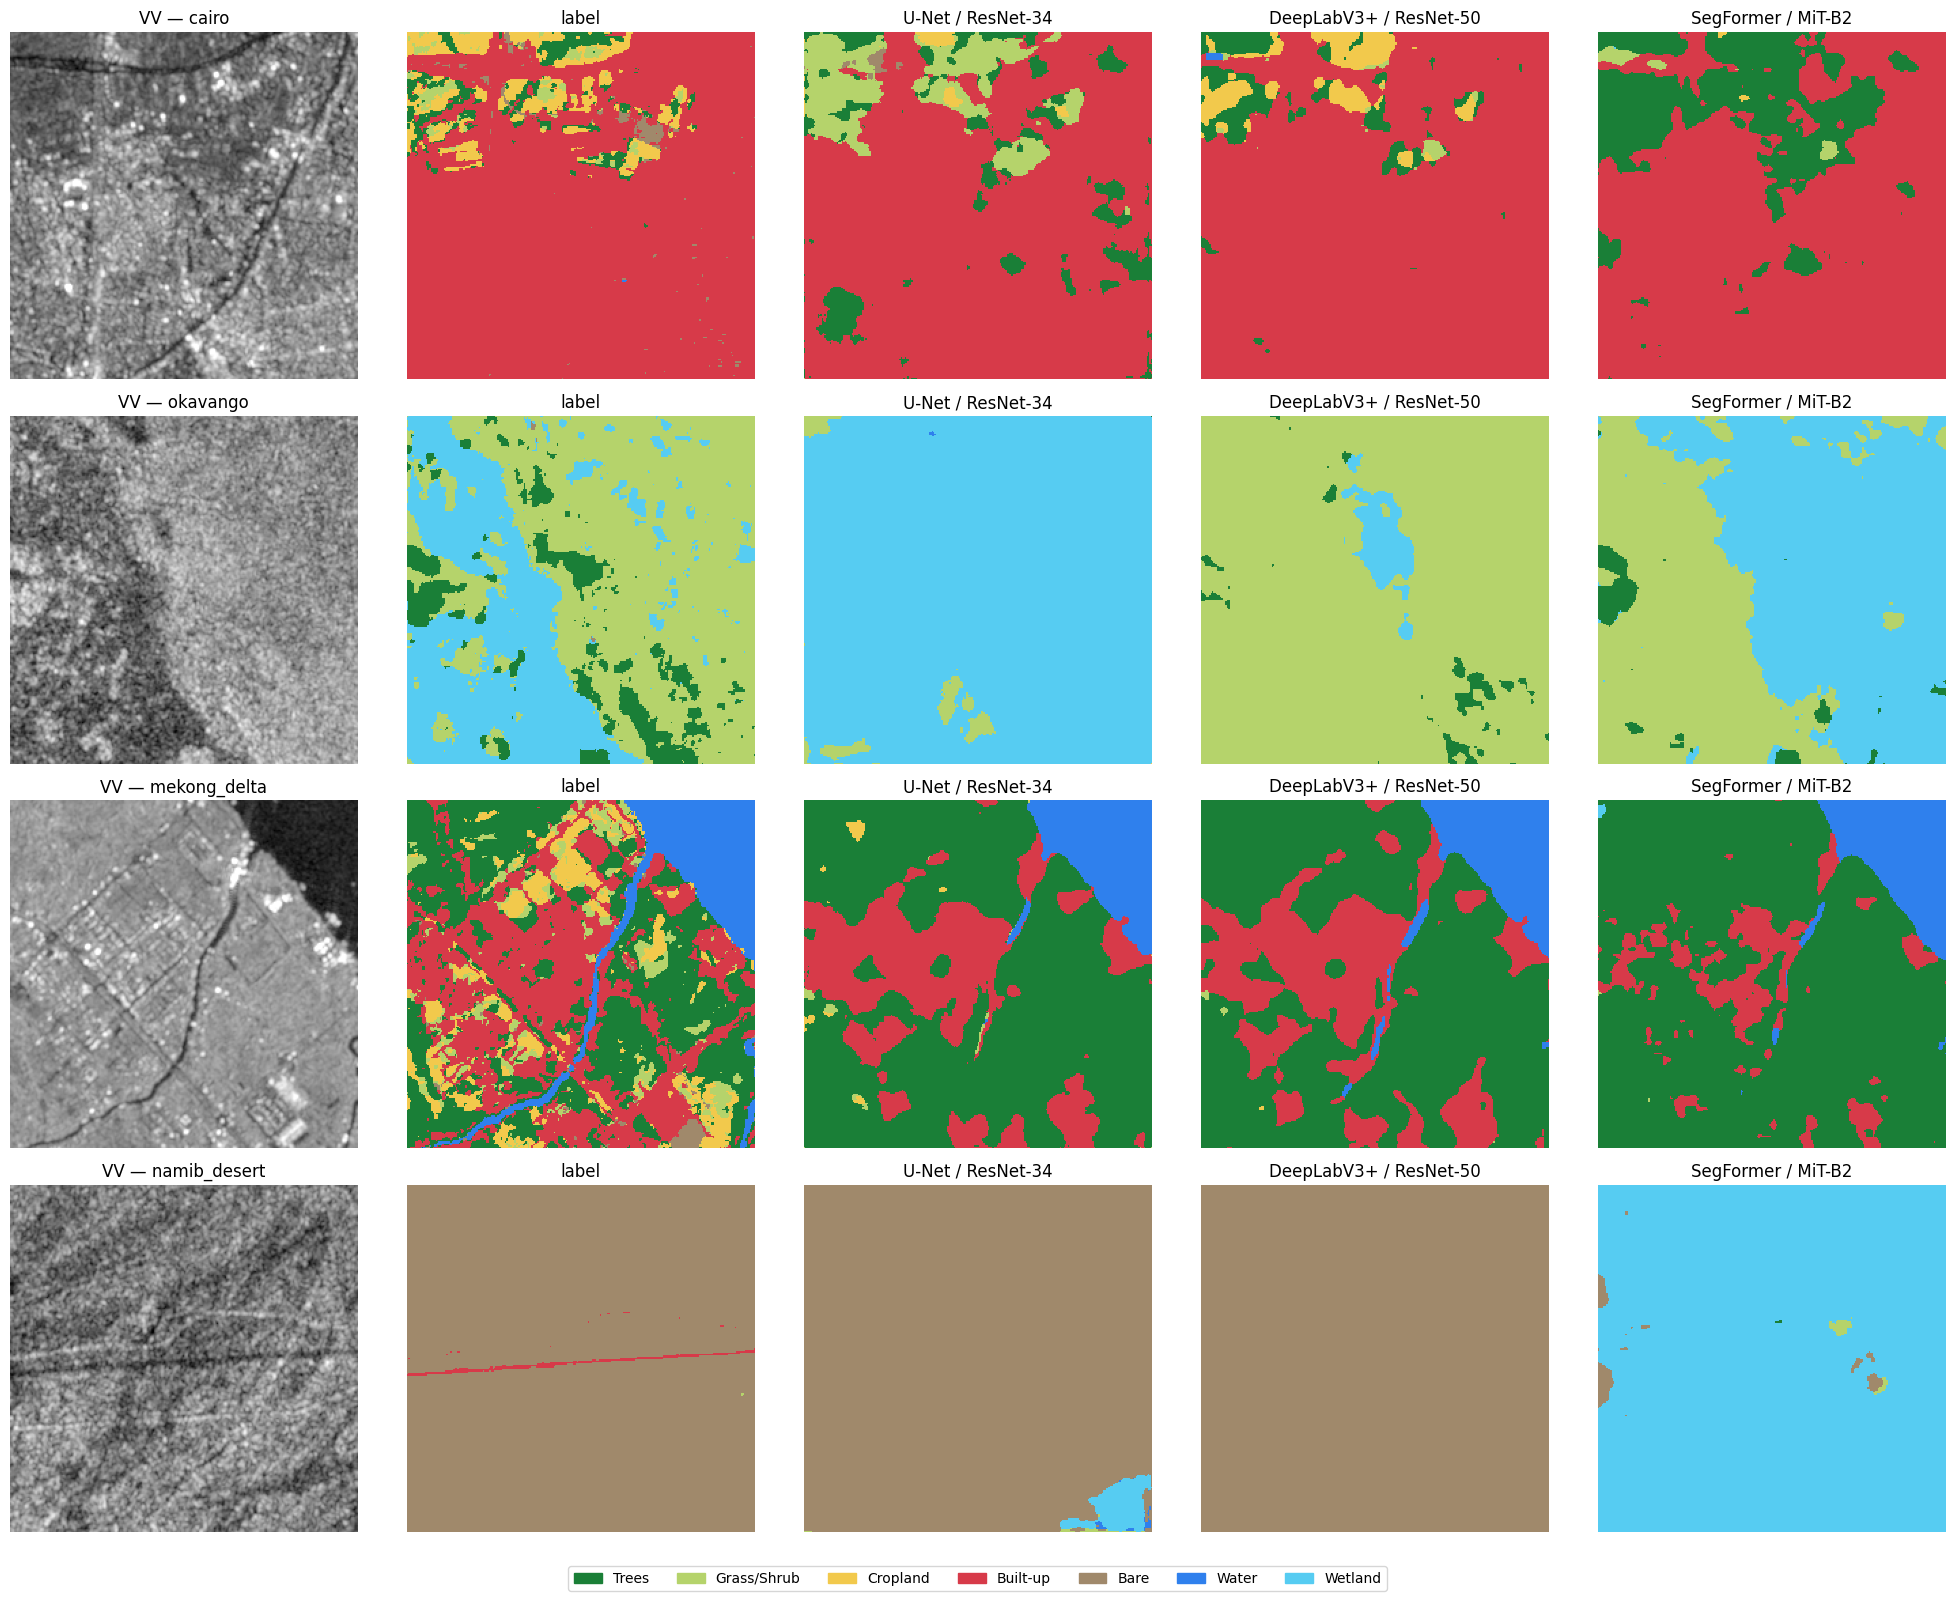

In [9]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
models = {}
for name, (run, make) in available.items():
    m = make().to(DEV); m.load_state_dict(torch.load(Path("runs") / run / "best.pth", map_location=DEV)); m.eval()
    models[name] = m

picks = [k for k in range(len(test_ds)) if month_of[k] == 6]                  # July
picks = [picks[i] for i in np.linspace(0, len(picks) - 1, 4).astype(int)]
fig, ax = plt.subplots(len(picks), 2 + len(models), figsize=(4 * (2 + len(models)), 4 * len(picks)), squeeze=False)
for r, k in enumerate(picks):
    x, y = test_ds[k]
    ax[r, 0].imshow(x[0], cmap="gray"); ax[r, 0].set_title(f"VV — {region_of[k]}")
    ax[r, 1].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 1].set_title("label")
    for c, (name, m) in enumerate(models.items()):
        with torch.no_grad():
            p = m(x[None].to(DEV)).argmax(1)[0].cpu().numpy()
        ax[r, 2 + c].imshow(p, cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 2 + c].set_title(name)
    for a in ax[r]: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=NC)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig("runs/comparison_test_examples.png", dpi=110); plt.show()

## 6. What to write down

* Which model wins on **validation mIoU** (choice) and its **test** OA / mIoU / per-class IoU & F1 (report).
* Which classes each model is better at — e.g. does wider context (DeepLabV3+, SegFormer) reduce Bare ↔ Built-up confusion?
* Cost: parameters and training time.
* Generalisation (per region) and seasonal stability (per month).

All tables and figures are saved in `runs/` (`comparison_*.csv`, `comparison_*.png`, `test_confusion_*.png`).